# Módulo 4 — Regla de Simpson (prototipo en Python)

**Proyecto:** Cálculo Integral Interactivo · Matemáticas II · UTP

Implementamos la regla de Simpson **desde cero**, deducimos su fórmula con SymPy y comprobamos los ejemplos del módulo 4.

$$S_n=\frac{\Delta x}{3}\Big[f(x_0)+4f(x_1)+2f(x_2)+4f(x_3)+\cdots+2f(x_{n-2})+4f(x_{n-1})+f(x_n)\Big],\qquad n\text{ par}$$

## 1. Preparación

In [1]:
# --- Bibliotecas que usaremos ---
import numpy as np                 # cálculo numérico con arreglos
import matplotlib.pyplot as plt    # gráficas
import sympy as sp                 # matemática simbólica: SOLO para el valor exacto y para verificar
                                   # (los algoritmos numéricos los escribimos nosotros desde cero)

x = sp.symbols("x")                # símbolo matemático "x" para SymPy

def preparar(expr, a, b):
    """Convierte una expresión de SymPy en (f_numpy, valor_exacto).
    - f_numpy: función que acepta arreglos de NumPy.
    - valor_exacto: integral definida exacta (Teorema Fundamental del Cálculo), como número decimal."""
    f = sp.lambdify(x, expr, "numpy")
    exacto = float(sp.integrate(expr, (x, a, b)))
    return f, exacto

## 2. ¿De dónde sale $\dfrac{h}{3}(y_0+4y_1+y_2)$?
Tomamos tres puntos igualmente separados $(-h,y_0)$, $(0,y_1)$, $(h,y_2)$, ajustamos la parábola $p(t)=At^2+Bt+C$ que pasa por ellos y calculamos el área bajo ella con SymPy.

In [2]:
h, y0, y1, y2, t = sp.symbols("h y0 y1 y2 t")
A, B, C = sp.symbols("A B C")

p = A * t**2 + B * t + C                                   # parábola general
sol = sp.solve([p.subs(t, -h) - y0,                        # pasa por (-h, y0)
                p.subs(t, 0) - y1,                         # pasa por (0, y1)
                p.subs(t, h) - y2],                        # pasa por (h, y2)
               [A, B, C])
area = sp.integrate(p.subs(sol), (t, -h, h))               # área bajo la parábola entre -h y h
print("Área bajo la parábola =", sp.factor(sp.simplify(area)))

# Comprobamos que coincide con la fórmula de Simpson
assert sp.simplify(area - h * (y0 + 4 * y1 + y2) / 3) == 0
print("✔ Es exactamente h/3 · (y0 + 4·y1 + y2)")

Área bajo la parábola = h*(y0 + 4*y1 + y2)/3
✔ Es exactamente h/3 · (y0 + 4·y1 + y2)


## 3. Implementación desde cero
Cada parábola cubre **dos** subintervalos, así que $n$ debe ser par. Los coeficientes siguen el patrón $1,4,2,4,\dots,2,4,1$.

In [3]:
def simpson(f, a, b, n):
    """Regla de Simpson 1/3 con n subintervalos (n debe ser par)."""
    if n % 2 != 0:
        raise ValueError("La regla de Simpson necesita un n par.")
    xs = np.linspace(a, b, n + 1)
    ys = f(xs)
    dx = (b - a) / n
    coef = np.ones(n + 1)          # empezamos con todos los coeficientes en 1
    coef[1:-1:2] = 4               # posiciones impares (1, 3, 5, ...) -> 4
    coef[2:-1:2] = 2               # posiciones pares interiores (2, 4, ...) -> 2
    return dx / 3 * np.sum(coef * ys)

def trapecio(f, a, b, n):
    """(Del cuaderno 2) Para comparar."""
    xs = np.linspace(a, b, n + 1); ys = f(xs); dx = (b - a) / n
    return dx / 2 * (ys[0] + 2 * np.sum(ys[1:-1]) + ys[-1])

# El programa debe negarse a trabajar con n impar
try:
    simpson(lambda z: z, 0, 1, 3)
except ValueError as e:
    print("Error esperado:", e)

Error esperado: La regla de Simpson necesita un n par.


## 4. Ejemplo 1 del módulo: $\int_0^2 x^2\,dx$ con $n=4$ (resultado exacto)

In [4]:
f1, exacto1 = preparar(x**2, 0, 2)
S = simpson(f1, 0, 2, 4)
print(f"S4 = {S:.6f}   (a mano: 8/3 = {8/3:.6f})")
print(f"Exacto = {exacto1:.6f}   error = {abs(S - exacto1):.2e}")
assert np.isclose(S, 8 / 3)
print("✔ Coincide con el ejemplo 1 del módulo 4")

S4 = 2.666667   (a mano: 8/3 = 2.666667)
Exacto = 2.666667   error = 0.00e+00
✔ Coincide con el ejemplo 1 del módulo 4


## 5. Ejemplo 2 del módulo: $\int_0^\pi \operatorname{sen}(x)\,dx$ con $n=4$

In [5]:
f2, exacto2 = preparar(sp.sin(x), 0, sp.pi)
b2 = float(sp.pi)
S = simpson(f2, 0, b2, 4)
T = trapecio(f2, 0, b2, 4)
print(f"S4 = {S:.5f}   (a mano: 2.0046)     error = {abs(S - exacto2):.5f}")
print(f"T4 = {T:.5f}   (a mano: 1.8961)     error = {abs(T - exacto2):.5f}")
print(f"Simpson es {abs(T - exacto2) / abs(S - exacto2):.1f} veces más precisa que el trapecio aquí")
assert np.isclose(S, 2.0046, atol=1e-4)
print("✔ Coincide con el ejemplo 2 del módulo 4")

S4 = 2.00456   (a mano: 2.0046)     error = 0.00456
T4 = 1.89612   (a mano: 1.8961)     error = 0.10388
Simpson es 22.8 veces más precisa que el trapecio aquí
✔ Coincide con el ejemplo 2 del módulo 4


## 6. Simpson es exacta para polinomios de grado ≤ 3
Probamos con un cubo, una función de grado 3 y una de grado 4.

In [6]:
for expr, nombre in [(x**3 - 2 * x + 1, "grado 3: x³ − 2x + 1"), (x**4, "grado 4: x⁴")]:
    f, ex = preparar(expr, 0, 2)
    S = simpson(f, 0, 2, 2)        # solo UNA parábola (n = 2)
    print(f"{nombre:<24} S2 = {S:.6f}   exacto = {ex:.6f}   error = {abs(S - ex):.2e}")

grado 3: x³ − 2x + 1     S2 = 2.000000   exacto = 2.000000   error = 0.00e+00
grado 4: x⁴              S2 = 6.666667   exacto = 6.400000   error = 2.67e-01


## 7. Visualización de las parábolas

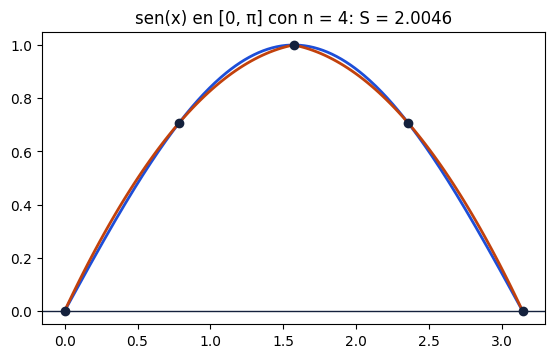

In [7]:
def lagrange(x0, y0, x1, y1, x2, y2, z):
    """Parábola que pasa por tres puntos, evaluada en z (interpolación de Lagrange)."""
    return (y0 * (z - x1) * (z - x2) / ((x0 - x1) * (x0 - x2)) +
            y1 * (z - x0) * (z - x2) / ((x1 - x0) * (x1 - x2)) +
            y2 * (z - x0) * (z - x1) / ((x2 - x0) * (x2 - x1)))

def dibujar_simpson(f, a, b, n, ax):
    xs = np.linspace(a, b, 400)
    ax.plot(xs, f(xs), lw=2, color="#1d4ed8", label="f(x)")
    nodos = np.linspace(a, b, n + 1)
    for k in range(0, n, 2):                                   # una parábola por cada par de franjas
        x0, x1, x2 = nodos[k], nodos[k + 1], nodos[k + 2]
        z = np.linspace(x0, x2, 60)
        ax.plot(z, lagrange(x0, f(x0), x1, f(x1), x2, f(x2), z), color="#c2410c", lw=2)
    ax.plot(nodos, f(nodos), "o", color="#14213d")
    ax.axhline(0, color="#14213d", lw=1)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
dibujar_simpson(f2, 0, b2, 4, ax)
ax.set_title(f"sen(x) en [0, π] con n = 4: S = {simpson(f2, 0, b2, 4):.4f}")
plt.show()

## 8. Orden de convergencia
Para Simpson esperamos que el error baje mucho más rápido: $p=\log_2\big(E(n)/E(2n)\big)$ debería acercarse a 4.

   n |  error Simpson | p Simpson | error trapecio | p trapecio
----------------------------------------------------------------
   2 |      5.793e-04 |       nan |      3.565e-02 |        nan
   4 |      3.701e-05 |     3.968 |      8.940e-03 |      1.996
   8 |      2.326e-06 |     3.992 |      2.237e-03 |      1.999
  16 |      1.456e-07 |     3.998 |      5.593e-04 |      2.000
  32 |      9.103e-09 |     3.999 |      1.398e-04 |      2.000
  64 |      5.690e-10 |     4.000 |      3.496e-05 |      2.000


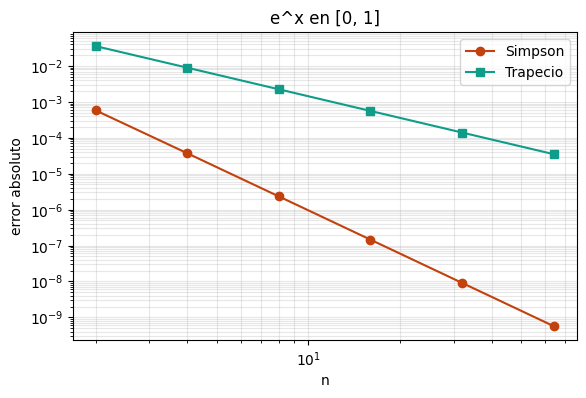

In [8]:
f3, exacto3 = preparar(sp.exp(x), 0, 1)
ns = [2, 4, 8, 16, 32, 64]
errS = [abs(simpson(f3, 0, 1, n) - exacto3) for n in ns]
errT = [abs(trapecio(f3, 0, 1, n) - exacto3) for n in ns]

print(f"{'n':>4} | {'error Simpson':>14} | {'p Simpson':>9} | {'error trapecio':>14} | {'p trapecio':>10}")
print("-" * 64)
for k, n in enumerate(ns):
    pS = np.log2(errS[k - 1] / errS[k]) if k > 0 else float("nan")
    pT = np.log2(errT[k - 1] / errT[k]) if k > 0 else float("nan")
    print(f"{n:>4} | {errS[k]:>14.3e} | {pS:>9.3f} | {errT[k]:>14.3e} | {pT:>10.3f}")

plt.figure(figsize=(6.5, 4))
plt.loglog(ns, errS, "o-", label="Simpson", color="#c2410c")
plt.loglog(ns, errT, "s-", label="Trapecio", color="#0f9d8a")
plt.xlabel("n"); plt.ylabel("error absoluto"); plt.title("e^x en [0, 1]")
plt.legend(); plt.grid(True, which="both", alpha=0.3); plt.show()

## Preguntas para pensar

1. ¿Por qué Simpson resulta exacta para cubos? (Pista: una parábola ajustada a tres puntos de un polinomio de grado 3... ¿qué error comete?) Formula una hipótesis antes de buscarla en tu texto guía.
2. Si tienes 101 nodos (n = 100), ¿puedes usar Simpson? ¿Y con 100 nodos? Explica por qué con lo que dibujaste en la sección 7.
3. **Ejercicio:** modifica `simpson` para que, si `n` es impar, lo suba automáticamente al siguiente par en lugar de dar error. ¿Qué ventajas y desventajas tiene esa decisión?